## v5a3

In [1]:
import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import numpy as np
from scipy.stats import beta, gamma, lognorm, norm, uniform
import math
from dask_cuda import LocalCUDACluster
from dask.distributed import Client, progress

warnings.filterwarnings('ignore')
cp.random.seed(42)

In [2]:
# %% [markdown]
## 2. Global Parameters & GPU Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035 # Fixed
POP_SIZE = 62000 # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017 # Fixed
INFLATION_RATE = 0.03 # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE)**(START_YEAR - COST_REFERENCE_YEAR) # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = cp.arange(0, 95, 5) # Fixed
AGE_DIST = cp.array([ # Fixed demographic distribution
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54]) # Fixed life expectancy for severe/mild
ABS_MORT = cp.array([ # Fixed baseline mortality rates
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,0.0011,0.0019,
    0.0035,0.0055,0.0085,0.0130,0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = { # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003, (0, (20, 24)): 0.008, (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007, (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001, (1, (20, 24)): 0.003, (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003, (1, (35, 45)): 0.001
}

# Employment costs (assumed fixed structural values)
EMP_CP = cp.array([0, 10000, 0]) * INFLATION_FACTOR

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = ['epilepsy', 'asd', 'mental'] # Based on previous code, not the paper's full list of costs

# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {'dist': 'fixed', 'value': mean} # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {'dist': 'gamma', 'shape': shape, 'scale': scale}

# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {'dist': 'fixed', 'value': mean}
    variance = std_dev**2
    # Ensure variance is valid for beta distribution: var < mean * (1 - mean)
    # If not, adjust SD slightly or fallback to uniform/fixed
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        # A common heuristic is to cap variance to be just under the max possible
        # Or, if this happens, it means the specified SD is very wide for a beta
        # Let's adjust SD down to make it valid, or pick uniform
        # For this case, we'll make a slight adjustment to the variance
        variance = mean * (1 - mean) * 0.99 # Cap at 99% of max possible variance
        # Recalculate std_dev from the adjusted variance
        std_dev = math.sqrt(variance)

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)
    
    if alpha <= 0 or beta_param <= 0: # Ensure positive parameters after adjustment
        # Fallback to a narrow uniform if calculated alpha/beta are invalid
        return {'dist': 'uniform', 'low': max(0, mean - 0.01), 'high': min(1, mean + 0.01)}
    return {'dist': 'beta', 'alpha': alpha, 'beta': beta_param}

# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions, assuming 20% CV for SD where not specified)
    # Mean and SD based on typical values or a reasonable assumption if not from paper.
    'cost_inp_mild': get_gamma_params(5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20),
    'cost_inp_severe': get_gamma_params(15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20),
    'cost_outp_mild': get_gamma_params(1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20),
    'cost_outp_severe': get_gamma_params(3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20),
    'cost_pharm_mild': get_gamma_params(200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20),
    'cost_pharm_severe': get_gamma_params(500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20),
    'edu0_sup0': get_gamma_params(16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15), # 15% CV
    'edu0_sup1': get_gamma_params(27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15),
    'edu0_sup2': get_gamma_params(46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15),
    'edu1_sup0': get_gamma_params(18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15),
    'edu1_sup1': get_gamma_params(30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15),
    'edu1_sup2': get_gamma_params(49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15),
    'respite': get_gamma_params(13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20),
    'mobility': get_gamma_params(2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20),
    'welfare_mild': get_gamma_params(3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20),
    'welfare_severe': get_gamma_params(8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20),
    'morb_cost_epilepsy': get_gamma_params(2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20),
    'morb_cost_asd': get_gamma_params(1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20),
    'morb_cost_mental': get_gamma_params(1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20),
    'wgs_diag_cost_adjustment': {'dist': 'normal', 'loc': -1000 * INFLATION_FACTOR, 'scale': 100 * INFLATION_FACTOR}, # Negative for cost saving, smaller SD

    # Utilities (Beta distributions, assuming reasonable SDs for parameters bounded 0-1)
    'u_base_mild': get_beta_params(0.78, 0.02), # Smaller SD for utilities
    'u_base_severe': get_beta_params(0.65, 0.03),
    'u_decay': get_beta_params(0.0005, 0.00005), # Adjusted SD for better beta fit
    'u_diag': get_beta_params(0.02, 0.002),
    'u_carer': get_beta_params(0.05, 0.005),
    'morb_qaly_epilepsy': get_beta_params(0.04, 0.005),
    'morb_qaly_asd': get_beta_params(0.03, 0.005),
    'morb_qaly_mental': get_beta_params(0.05, 0.005),
    'wgs_diag_qaly_adjustment': get_beta_params(0.01, 0.001),

    # Probabilities / Rates (Beta for probabilities, Log-normal for multipliers on rates)
    'mort_hr_mild': {'dist': 'lognormal', 's': 0.1, 'scale': 2.0}, # Mean 2.0, SD of ~0.2
    'mort_hr_severe': {'dist': 'lognormal', 's': 0.1, 'scale': 4.0}, # Mean 4.0, SD of ~0.4
    'morb_prob_epilepsy': get_beta_params(0.25, 0.03), # Smaller SD
    'morb_prob_asd': get_beta_params(0.30, 0.03),
    'morb_prob_mental': get_beta_params(0.35, 0.04),
    'familial_prop': {'dist': 'beta', 'alpha': 30, 'beta': 150}, # Original PSA parameter
    'yield_wgs': {'dist': 'beta', 'alpha': 45, 'beta': 55}, # Original PSA parameter
    'severity_mild_prop': get_beta_params(0.70, 0.03), # Proportion of mild severity, severe is 1 - this
    'fertility_multiplier': {'dist': 'lognormal', 's': 0.1, 'scale': 1.0}, # Multiplier for all base fertility rates

    # Fixed parameters (will be sampled as their single value)
    'min_test_age': {'dist': 'fixed', 'value': 0}, # Default value, can be overridden in subgroup analysis
}

# Helper function to sample from the defined distributions
def sample_params_from_dist(dist_dict, seed=None):
    if seed is not None:
        np.random.seed(seed) # Set NumPy seed for SciPy distributions
    
    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        if dist_info['dist'] == 'beta':
            sampled_params[param_name] = beta.rvs(dist_info['alpha'], dist_info['beta'])
        elif dist_info['dist'] == 'gamma':
            sampled_params[param_name] = gamma.rvs(a=dist_info['shape'], scale=dist_info['scale'])
        elif dist_info['dist'] == 'lognormal':
            # scipy.stats.lognorm takes s (shape), loc (offset), scale (exp(meanlog))
            sampled_params[param_name] = lognorm.rvs(s=dist_info['s'], scale=dist_info['scale'])
        elif dist_info['dist'] == 'normal':
            sampled_params[param_name] = norm.rvs(loc=dist_info['loc'], scale=dist_info['scale'])
        elif dist_info['dist'] == 'uniform':
            sampled_params[param_name] = uniform.rvs(loc=dist_info['low'], scale=dist_info['high'] - dist_info['low'])
        elif dist_info['dist'] == 'fixed':
            sampled_params[param_name] = dist_info['value']
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
            
    # Handle interdependent parameters
    # Severity distribution: if mild_prop is sampled, severe_prop is derived
    if 'severity_mild_prop' in sampled_params:
        sampled_params['severity_severe_prop'] = 1.0 - sampled_params['severity_mild_prop']
    
    return sampled_params

# Re-package arrays/vectors that depend on sampled parameters
def prepare_gpu_params(sampled_params):
    # Costs
    COST_INP_CP_sampled = cp.array([sampled_params['cost_inp_mild'], sampled_params['cost_inp_severe']])
    COST_OUTP_CP_sampled = cp.array([sampled_params['cost_outp_mild'], sampled_params['cost_outp_severe']])
    COST_PHARM_CP_sampled = cp.array([sampled_params['cost_pharm_mild'], sampled_params['cost_pharm_severe']])
    EDU_SAMPLED = cp.array([
        [sampled_params['edu0_sup0'], sampled_params['edu0_sup1'], sampled_params['edu0_sup2']],
        [sampled_params['edu1_sup0'], sampled_params['edu1_sup1'], sampled_params['edu1_sup2']]
    ])
    WELFARE_CP_sampled = cp.array([sampled_params['welfare_mild'], sampled_params['welfare_severe']])
    MORB_COST_CP_sampled = cp.array([
        sampled_params['morb_cost_epilepsy'],
        sampled_params['morb_cost_asd'],
        sampled_params['morb_cost_mental']
    ])
    
    # Utilities
    U_BASE_CP_sampled = cp.array([sampled_params['u_base_mild'], sampled_params['u_base_severe']])
    MORB_QALY_CP_sampled = cp.array([
        sampled_params['morb_qaly_epilepsy'],
        sampled_params['morb_qaly_asd'],
        sampled_params['morb_qaly_mental']
    ])
    
    # Mortality HRs
    MORT_HR_sampled = cp.array([sampled_params['mort_hr_mild'], sampled_params['mort_hr_severe']])

    # Morbidity Probabilities
    MORB_PROB_SAMPLED = {
        'epilepsy': sampled_params['morb_prob_epilepsy'],
        'asd': sampled_params['morb_prob_asd'],
        'mental': sampled_params['morb_prob_mental']
    }
    
    # Severity Distribution
    SEVERITY_DIST_SAMPLED = cp.array([sampled_params['severity_mild_prop'], sampled_params['severity_severe_prop']])

    # Fertility Rates
    FERT_RATES_GPU_SAMPLED = FERT_RATES_GPU.copy()
    FERT_RATES_GPU_SAMPLED['rate'] *= sampled_params['fertility_multiplier']
    
    # Return a dictionary of CuPy arrays and dicts needed by the simulation
    return {
        'COST_INP_CP': COST_INP_CP_sampled,
        'COST_OUTP_CP': COST_OUTP_CP_sampled,
        'COST_PHARM_CP': COST_PHARM_CP_sampled,
        'EDU': EDU_SAMPLED, # This will replace EDU0/EDU1 in _cost_qaly
        'RESPITE': sampled_params['respite'],
        'MOBILITY': sampled_params['mobility'],
        'WELFARE_CP': WELFARE_CP_sampled,
        'EMP_CP': EMP_CP, # Fixed parameter
        'MORB_COST_CP': MORB_COST_CP_sampled,
        'WGS_DIAG_COST_ADJUSTMENT': sampled_params['wgs_diag_cost_adjustment'],
        'U_BASE_CP': U_BASE_CP_sampled,
        'U_DECAY': sampled_params['u_decay'],
        'U_DIAG': sampled_params['u_diag'],
        'U_CARER': sampled_params['u_carer'],
        'MORB_QALY_CP': MORB_QALY_CP_sampled,
        'WGS_DIAG_QALY_ADJUSTMENT': sampled_params['wgs_diag_qaly_adjustment'],
        'MORT_HR': MORT_HR_sampled,
        'MORB_PROB': MORB_PROB_SAMPLED,
        'familial_prop': sampled_params['familial_prop'],
        'yield_wgs': sampled_params['yield_wgs'],
        'min_test_age': sampled_params['min_test_age'],
        'SEVERITY_DIST': SEVERITY_DIST_SAMPLED,
        'FERT_RATES_GPU': FERT_RATES_GPU_SAMPLED, # Pass the adjusted DataFrame
        'DISCOUNT': DISCOUNT, # Pass fixed global parameters for clarity
        'INFLATION_FACTOR': INFLATION_FACTOR,
        'MORB_KEYS': MORB_KEYS # Pass MORB_KEYS here so it's accessible within the class
    }


# Build GPU lookup table for fertility rates (base rates before sampling multiplier)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

In [3]:
# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n, age_dist_param):
    # age_dist_param is expected to be AGE_DIST (fixed)
    idx = cp.random.choice(len(AGE_BREAKS), n, p=age_dist_param)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, current_params, arm='prospective'):
    # Uses current_params for severity_dist
    ages = sample_ages_gpu(n, AGE_DIST) # AGE_DIST is global fixed
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=current_params['SEVERITY_DIST']) # Now sampled
    familial = cp.random.random(n) < current_params['familial_prop'] # Now sampled
    diag = cp.zeros(n, bool) if arm == 'prospective' else (cp.random.random(n) < current_params['yield_wgs']) # Now sampled
    living = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4])) # Fixed proportions
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1])) # Fixed proportions
    uses_respite = cp.random.random(n) < 0.3 # Fixed probability
    needs_mobility = cp.random.random(n) < 0.2 # Fixed probability
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2])) # Fixed proportions
    ses = cp.random.choice(5, n) # Fixed proportions
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diag, 'living': living, 'employment': employment,
        'uses_respite': uses_respite, 'needs_mobility': needs_mobility,
        'school': school, 'support': support, 'ses': ses
    })
    # Add columns for outputs
    for col in ['annual_cost', 'annual_qaly', 'cost_health', 'cost_edu',
                'cost_respite', 'cost_mobility', 'cost_welfare',
                'cost_emp', 'cost_morbidity']:
        df[col] = 0.0
    return df

In [4]:
# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self, pop_size, current_params, arm='prospective'):
        self.arm = arm
        self.params = current_params # Store all sampled parameters
        self.pop = gen_population_gpu(pop_size, self.params, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy(); sev = df['severity'].to_cupy()
        # Ensure age index is within bounds for ABS_MORT
        age_indices = cp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
        # Use sampled MORT_HR
        surv = ABS_MORT[age_indices] * self.params['MORT_HR'][sev]
        mask = (cp.random.random(len(df)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self):
        df = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty: return
        # Use sampled FERT_RATES_GPU (which already has multiplier applied)
        mr = moms.merge(self.params['FERT_RATES_GPU'], on=['severity','age'], how='left').fillna(0)
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx)>0:
            # Pass familial_prop and SEVERITY_DIST from current_params for gen_population_gpu
            babies_params = {
                'familial_prop': self.params['familial_prop'],
                'SEVERITY_DIST': self.params['SEVERITY_DIST'],
                'yield_wgs': self.params['yield_wgs'] # Also needed by gen_population_gpu for 'diag' column
            }
            babies = gen_population_gpu(len(idx), babies_params, self.arm)
            babies['age'] = 0
            # Inherit 'familial' status from the mother
            flags = mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self):
        if self.arm != 'prospective': return
        df = self.pop
        # Use sampled yield_wgs and min_test_age
        mask = (~df['diagnosed']) & df['familial'] & (df['age'] >= self.params['min_test_age'])
        cnt = int(mask.sum())
        if cnt > 0:
            indices = df.index[mask]
            df.loc[indices, 'diagnosed'] = cp.random.random(cnt) < self.params['yield_wgs']
        self.pop = df

    def _cost_qaly(self, year):
        df = self.pop
        n = len(df)
        if n == 0: return

        # Use sampled DISCOUNT
        disc = 1 / ((1 + self.params['DISCOUNT'])**(year - START_YEAR))
        sev = df['severity'].to_cupy(); ages = df['age'].to_cupy()

        # Costs - use sampled parameters
        hc = (self.params['COST_INP_CP'][sev] + self.params['COST_OUTP_CP'][sev] + self.params['COST_PHARM_CP'][sev]) * disc
        rc = df['uses_respite'].to_cupy().astype(int) * self.params['RESPITE'] * disc
        mc = -df['needs_mobility'].to_cupy().astype(int) * self.params['MOBILITY'] * disc # Cost saving
        wc = self.params['WELFARE_CP'][sev] * disc
        emp = self.params['EMP_CP'][df['employment'].to_cupy()] * disc

        ec = cp.zeros(n, dtype=cp.float64)
        m0 = df['school'] == 0
        m1 = df['school'] == 1
        if not df.loc[m0].empty:
            # Use sampled EDU array
            ec[m0.to_cupy()] = self.params['EDU'][0, df.loc[m0,'support'].to_cupy()] * disc
        if not df.loc[m1].empty:
            # Use sampled EDU array
            ec[m1.to_cupy()] = self.params['EDU'][1, df.loc[m1,'support'].to_cupy()] * disc

        morb_cost = cp.zeros(n, dtype=cp.float64)
        base_rand = cp.random.random(n)
        # Use self.params['MORB_KEYS'] which is passed through prepare_gpu_params
        for i, k in enumerate(self.params['MORB_KEYS']):
            # Use sampled MORB_PROB and MORB_COST_CP
            m = (base_rand < self.params['MORB_PROB'][k])
            morb_cost += m.astype(cp.float64) * self.params['MORB_COST_CP'][i] * disc

        # Apply WGS-specific cost adjustment if in prospective arm and diagnosed
        if self.arm == 'prospective':
            m = df['diagnosed'].to_cupy()
            morb_cost += m.astype(cp.float64) * self.params['WGS_DIAG_COST_ADJUSTMENT'] * disc

        # QALYs - use sampled parameters
        morb_qaly = cp.zeros(n, dtype=cp.float64)
        for i, k in enumerate(self.params['MORB_KEYS']): # Use self.params['MORB_KEYS']
            # Use sampled MORB_PROB and MORB_QALY_CP
            m = (base_rand < self.params['MORB_PROB'][k])
            morb_qaly += m.astype(cp.float64) * self.params['MORB_QALY_CP'][i] * disc
        
        # Use sampled U_BASE_CP, U_DECAY, U_DIAG, U_CARER
        uq = self.params['U_BASE_CP'][sev] * cp.exp(-self.params['U_DECAY'] * cp.clip(ages - 20, 0, None))
        total_qaly = (uq + df['diagnosed'].to_cupy().astype(int) * self.params['U_DIAG'] + self.params['U_CARER']) * disc - morb_qaly

        # Apply WGS-specific QALY adjustment if in prospective arm and diagnosed
        if self.arm == 'prospective':
            m = df['diagnosed'].to_cupy()
            total_qaly += m.astype(cp.float64) * self.params['WGS_DIAG_QALY_ADJUSTMENT'] * disc

        # Assign back to DataFrame
        df['cost_health'] = hc
        df['cost_edu'] = ec
        df['cost_respite'] = rc
        df['cost_mobility'] = mc
        df['cost_welfare'] = wc
        df['cost_emp'] = emp
        df['cost_morbidity'] = morb_cost
        df['annual_cost'] = hc + ec + rc + mc + wc + emp + morb_cost
        df['annual_qaly'] = total_qaly
        self.pop = df

    def step(self, year):
        # Pass sampled parameters implicitly via self.params
        self._mortality()
        self._fertility()
        self._diagnosis()
        self.pop['age'] += 1
        self._cost_qaly(year)

In [5]:
# %% [markdown]
## 5. Run Helpers

def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    """Fast runner for aggregate results (dCost, dQALY). Used for PSA, Tornado.
    Accepts an optional seed_idx for probabilistic runs."""
    if seed_idx is not None:
        cp.random.seed(42 + seed_idx)
    else:
        # Default seed for deterministic/non-PSA runs for reproducibility
        cp.random.seed(42)

    # Prepare CuPy arrays from sampled parameters
    gpu_params = prepare_gpu_params(sampled_params)

    sim_r = PopulationSystemGPU(pop_size, gpu_params, 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, gpu_params, 'prospective')
    
    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0
    
    for yr in YEARS:
        sim_r.step(yr) # No more params argument
        if not sim_r.pop.empty:
            cum_r_c += float(sim_r.pop['annual_cost'].sum())
            cum_r_q += float(sim_r.pop['annual_qaly'].sum())
            
        sim_p.step(yr) # No more params argument
        if not sim_p.pop.empty:
            cum_p_c += float(sim_p.pop['annual_cost'].sum())
            cum_p_q += float(sim_p.pop['annual_qaly'].sum())

    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    """Detailed runner that returns aggregate results AND a per-year DataFrame."""
    outputs = []
    final_totals = {}

    # Prepare CuPy arrays from sampled parameters
    gpu_params = prepare_gpu_params(sampled_params)

    for arm in ['retrospective', 'prospective']:
        sim = PopulationSystemGPU(pop_size, gpu_params, arm)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr) # No more params argument
            df = sim.pop

            if df.empty:
                # Append a zero-row to maintain structure
                row_data = {
                    'arm': arm, 'year': yr, 'annual_cost': 0.0,
                    'cost_health': 0.0, 'cost_edu': 0.0, 'cost_respite': 0.0,
                    'cost_mobility': 0.0, 'cost_welfare': 0.0,
                    'cost_emp': 0.0, 'cost_morbidity': 0.0,
                    'costs': cum_c, 'qalys': cum_q,
                    **{f'ses_q{i}_pct': 0.0 for i in range(5)}
                }
                outputs.append(row_data)
                continue
            
            # Extract already-discounted annual components for detailed output
            hc  = float(df['cost_health'].sum())
            edu = float(df['cost_edu'].sum())
            rc  = float(df['cost_respite'].sum())
            mob = float(df['cost_mobility'].sum())
            wc  = float(df['cost_welfare'].sum())
            emp = float(df['cost_emp'].sum())
            mc  = float(df['cost_morbidity'].sum())
            
            annual_c_sum = float(df['annual_cost'].sum())
            annual_q_sum = float(df['annual_qaly'].sum())
            
            cum_c += annual_c_sum
            cum_q += annual_q_sum
            
            outputs.append({
                'arm': arm, 'year': yr,
                'annual_cost': annual_c_sum, # Crucial for budget impact
                'cost_health': hc, 'cost_edu': edu, 'cost_respite': rc,
                'cost_mobility': mob, 'cost_welfare': wc,
                'cost_emp': emp, 'cost_morbidity': mc,
                'costs': cum_c, 'qalys': cum_q,
                **{f'ses_q{i}_pct': float((df['ses'] == i).mean() * 100) for i in range(5)}
            })

        final_totals[arm] = {'cost': cum_c, 'qaly': cum_q}

    d_cost = final_totals['prospective']['cost'] - final_totals['retrospective']['cost']
    d_qaly = final_totals['prospective']['qaly'] - final_totals['retrospective']['qaly']

    return (d_cost, d_qaly), cudf.DataFrame(outputs)

--- Running Module 6: Deterministic Scenarios ---
  scenario         dCost        dQALY          ICER
0      low  1.288821e+08  1748.699477  73701.675245
1     base  1.562525e+08  2308.195556  67694.672398
2     high  1.245769e+08  2450.556056  50836.170517


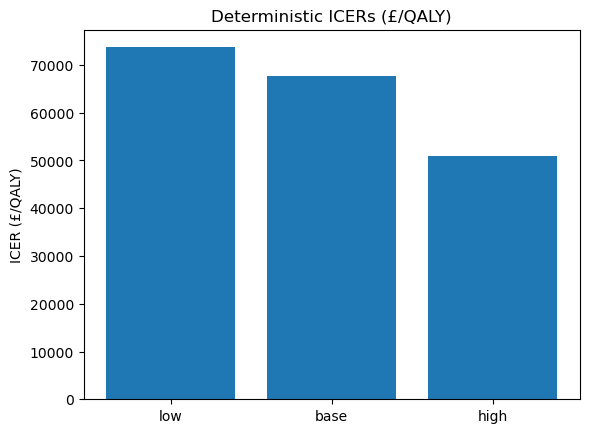

In [6]:
# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
# Define base values for parameters from their distributions for deterministic scenarios
# This calculates the mean for each distribution type
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v['dist'] == 'beta':
        base_mean_params[k] = v['alpha'] / (v['alpha'] + v['beta'])
    elif v['dist'] == 'gamma':
        base_mean_params[k] = v['shape'] * v['scale']
    elif v['dist'] == 'lognormal':
        base_mean_params[k] = v['scale'] * np.exp(v['s']**2 / 2) # Mean of lognormal
    elif v['dist'] == 'normal':
        base_mean_params[k] = v['loc']
    elif v['dist'] == 'uniform':
        base_mean_params[k] = (v['low'] + v['high']) / 2
    elif v['dist'] == 'fixed':
        base_mean_params[k] = v['value']

# Crucially, derive 'severity_severe_prop' for deterministic scenarios
if 'severity_mild_prop' in base_mean_params:
    base_mean_params['severity_severe_prop'] = 1.0 - base_mean_params['severity_mild_prop']

# Define specific scenarios, overriding only the relevant parameters
scenarios = {
    'low': {'familial_prop': base_mean_params['familial_prop'] - 0.05,
            'yield_wgs': base_mean_params['yield_wgs'] - 0.05},
    'base': {'familial_prop': base_mean_params['familial_prop'],
             'yield_wgs': base_mean_params['yield_wgs']},
    'high': {'familial_prop': base_mean_params['familial_prop'] + 0.05,
             'yield_wgs': base_mean_params['yield_wgs'] + 0.05}
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy() # Start with all mean values
    current_params_for_run.update(specific_override_params) # Override for the scenario
    
    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({'scenario': name, 'dCost': dc, 'dQALY': dq, 'ICER': icer})

det_df = cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)

plt.figure()
plt.bar(det_df['scenario'].to_arrow().to_pylist(), det_df['ICER'].to_arrow().to_pylist())
plt.title('Deterministic ICERs (£/QALY)')
plt.ylabel('ICER (£/QALY)')
plt.show()

In [7]:
# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask-CUDA cluster for parallel processing
cluster = LocalCUDACluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask-CUDA...")

# Prepare arguments for parallel map
psa_args = []
for i in range(psa_n):
    # Sample all parameters for this PSA run
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed=i) # Pass seed for reproducibility
    psa_args.append((sampled_params, 8000, i)) # (params_dict, pop_size, seed_idx)

# Map the run_sim function across the cluster
futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures) # Show progress bar

# Gather results
results = client.gather(futures)

# Populate psa_out from gathered results, including all sampled parameters
for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0] # Retrieve the full dictionary of sampled parameters
    row_data = {
        'run': i, 
        'dCost': dc, 
        'dQALY': dq,
    }
    # Add all sampled parameters to the row_data
    row_data.update(original_sampled_params)
    psa_out.append(row_data)

psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv', index=False)
print("PSA results saved to psa_samples.csv")

# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


--- Running Module 7: Probabilistic Sensitivity Analysis ---
Dask dashboard link: http://127.0.0.1:44762/status
Running 300 PSA simulations in parallel using Dask-CUDA...
PSA results saved to psa_samples.csv
Dask cluster closed.



--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---


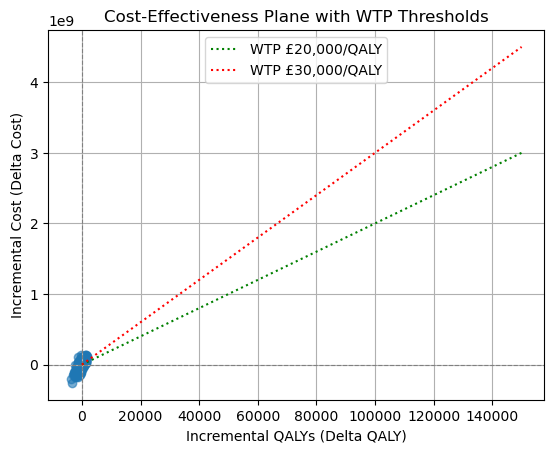

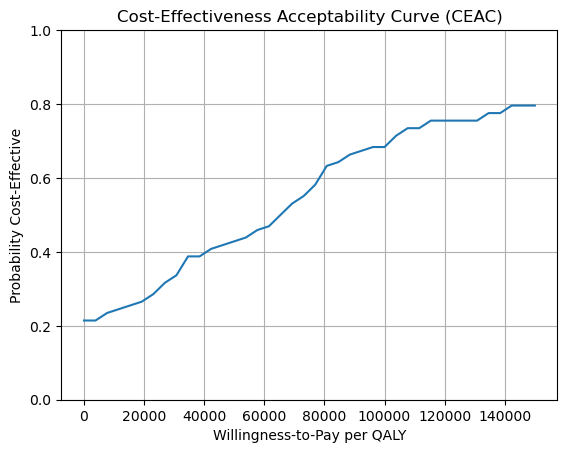

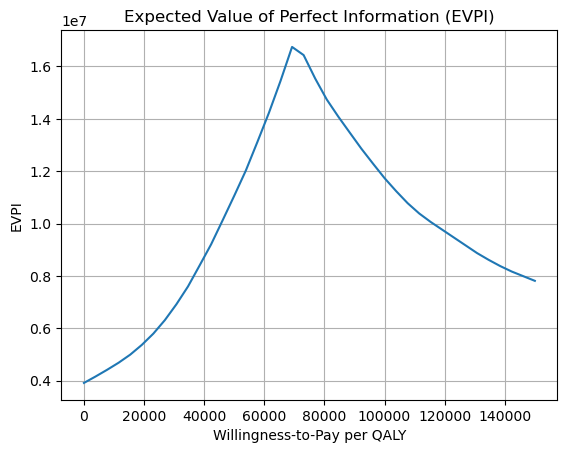

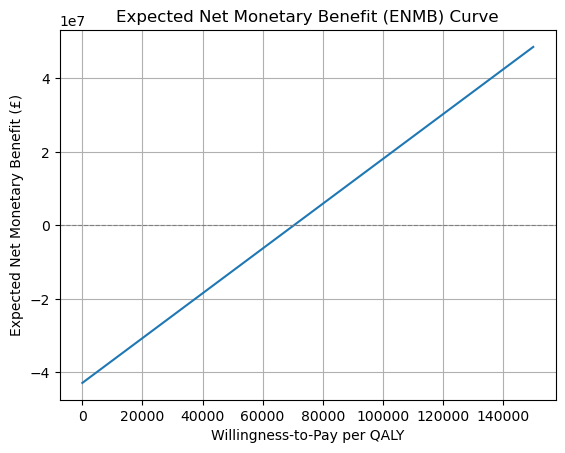

In [8]:
# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = cp.linspace(0, 150000, 40)
dcost = psa_df['dCost'].to_cupy()
dqaly = psa_df['dQALY'].to_cupy()

# Filter out non-positive QALYs for stable NB calculation
valid_psa = dqaly > 0
nb = dqaly[valid_psa, None] * wtp[None, :] - dcost[valid_psa, None]

# CE-Plane scatter with Quadrant Analysis
plt.figure()
plt.scatter(dqaly.get(), dcost.get(), alpha=0.6)
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8) # X-axis for dQALY=0
plt.axhline(y=0, color='grey', linestyle='--', linewidth=0.8) # Y-axis for dCost=0
# Add WTP thresholds
plt.plot(wtp.get(), wtp.get() * 20000, color='green', linestyle=':', label='WTP £20,000/QALY')
plt.plot(wtp.get(), wtp.get() * 30000, color='red', linestyle=':', label='WTP £30,000/QALY')
plt.xlabel('Incremental QALYs (Delta QALY)')
plt.ylabel('Incremental Cost (Delta Cost)')
plt.title('Cost-Effectiveness Plane with WTP Thresholds')
plt.grid(True)
plt.legend()
plt.show()

# CEAC
prob = (nb > 0).mean(axis=0)
plt.figure()
plt.plot(wtp.get(), prob.get())
plt.title('Cost-Effectiveness Acceptability Curve (CEAC)')
plt.xlabel('Willingness-to-Pay per QALY')
plt.ylabel('Probability Cost-Effective')
plt.ylim(0, 1)
plt.grid(True)
plt.show()

# EVPI - Corrected formula
evpi = cp.mean(cp.maximum(0, nb), axis=0) - cp.maximum(0, cp.mean(nb, axis=0))
plt.figure()
plt.plot(wtp.get(), evpi.get())
plt.title('Expected Value of Perfect Information (EVPI)')
plt.xlabel('Willingness-to-Pay per QALY')
plt.ylabel('EVPI')
plt.grid(True)
plt.show()

# ENMB (Expected Net Monetary Benefit) Curve
enmb = cp.mean(nb, axis=0)
plt.figure()
plt.plot(wtp.get(), enmb.get())
plt.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
plt.title('Expected Net Monetary Benefit (ENMB) Curve')
plt.xlabel('Willingness-to-Pay per QALY')
plt.ylabel('Expected Net Monetary Benefit (£)')
plt.grid(True)
plt.show()


--- Running Module 9: One-Way Sensitivity (Tornado) ---


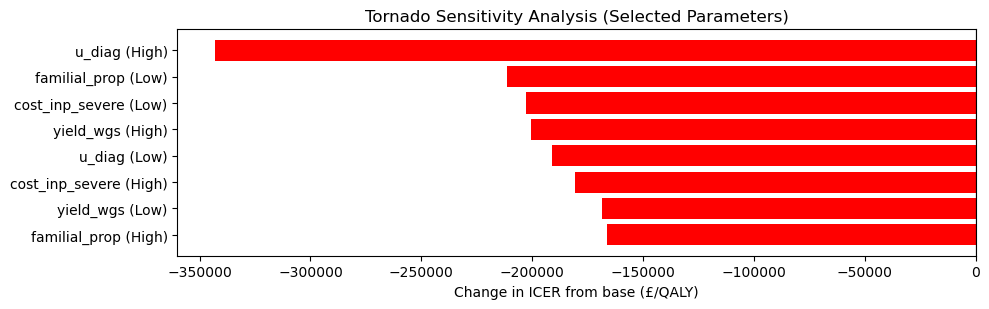

In [9]:
# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []

# Get the mean/base values for all parameters
base_params = {}
for k, v in DISTRIBUTIONS.items():
    if v['dist'] == 'beta':
        base_params[k] = v['alpha'] / (v['alpha'] + v['beta'])
    elif v['dist'] == 'gamma':
        base_params[k] = v['shape'] * v['scale']
    elif v['dist'] == 'lognormal':
        base_params[k] = v['scale'] * np.exp(v['s']**2 / 2) # Mean of lognormal
    elif v['dist'] == 'normal':
        base_params[k] = v['loc']
    elif v['dist'] == 'uniform':
        base_params[k] = (v['low'] + v['high']) / 2
    elif v['dist'] == 'fixed':
        base_params[k] = v['value']

# Crucially, derive 'severity_severe_prop' for deterministic scenarios
if 'severity_mild_prop' in base_params:
    base_params['severity_severe_prop'] = 1.0 - base_params['severity_mild_prop']

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

# Select a few key parameters to vary for the Tornado plot.
# These should be single parameters, not arrays or complex ones.
# We'll pick 'familial_prop', 'yield_wgs', 'u_diag', 'cost_inp_severe'.
# We need to consider how to vary them based on their distribution types.

tornado_params_to_vary = ['familial_prop', 'yield_wgs', 'u_diag', 'cost_inp_severe']

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    
    # Determine the range for sensitivity analysis based on distribution type
    if dist_info['dist'] == 'beta':
        # Use mean +/- 2 * std_dev for a range, ensuring it stays within [0,1]
        mean_val = dist_info['alpha'] / (dist_info['alpha'] + dist_info['beta'])
        variance = (dist_info['alpha'] * dist_info['beta']) / ((dist_info['alpha'] + dist_info['beta'])**2 * (dist_info['alpha'] + dist_info['beta'] + 1))
        std_dev = math.sqrt(variance)
        low_val = max(0, mean_val - 2 * std_dev)
        high_val = min(1, mean_val + 2 * std_dev)
    elif dist_info['dist'] == 'gamma':
        mean_val = dist_info['shape'] * dist_info['scale']
        std_dev = math.sqrt(dist_info['shape'] * dist_info['scale']**2)
        low_val = max(0, mean_val - 2 * std_dev)
        high_val = mean_val + 2 * std_dev # Gamma is skewed, so just use 2 SD for high
    elif dist_info['dist'] == 'normal':
        mean_val = dist_info['loc']
        std_dev = dist_info['scale']
        low_val = mean_val - 2 * std_dev
        high_val = mean_val + 2 * std_dev
    elif dist_info['dist'] == 'lognormal':
        # Scale is exp(mu), s is sigma of lognormal. Mean is exp(mu + sigma^2/2)
        # Using scale as approximate mean for variation
        mean_val = dist_info['scale'] * np.exp(dist_info['s']**2 / 2)
        std_dev = mean_val * np.sqrt(np.exp(dist_info['s']**2) - 1)
        # For tornado, vary by a fixed percentage around the mean, e.g., +/- 10%
        low_val = mean_val * 0.90
        high_val = mean_val * 1.10
    elif dist_info['dist'] == 'uniform':
        low_val = dist_info['low']
        high_val = dist_info['high']
        mean_val = (low_val + high_val) / 2
    elif dist_info['dist'] == 'fixed':
        low_val = high_val = mean_val = dist_info['value']
    else:
        # Skip unknown distributions for tornado
        continue

    # Evaluate at low and high values
    for val in [low_val, high_val]:
        p_temp = base_params.copy() # Start with all base parameters
        p_temp[param_name] = val # Override the specific parameter
        
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        
        # Determine if it's low or high change based on original mean
        change_type = 'Low' if val < mean_val else 'High'
        tornado.append({'param': param_name, 'change_type': change_type, 'ICER': icer})

tor_df = cudf.DataFrame(tornado)

# Calculate difference from base ICER for plotting
tor_df['ICER_diff'] = tor_df['ICER'] - base_icer

# Sort by the absolute difference for tornado plot
tor_df['abs_diff'] = tor_df['ICER_diff'].abs()
tor_df = tor_df.sort_values(by='abs_diff', ascending=True)

# Plotting
plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8)) # Adjust figure size dynamically
y_pos = np.arange(len(tor_df))
bars = tor_df['ICER_diff'].to_arrow().to_pylist()
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.to_pandas().iterrows()] # Use pandas iterrows

colors = ['red' if x < 0 else 'green' for x in bars]

plt.barh(labels, bars, color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Change in ICER from base (£/QALY)')
plt.title('Tornado Sensitivity Analysis (Selected Parameters)')
plt.tight_layout()
plt.show()


--- Running Module 10: Sub-group Analyses ---


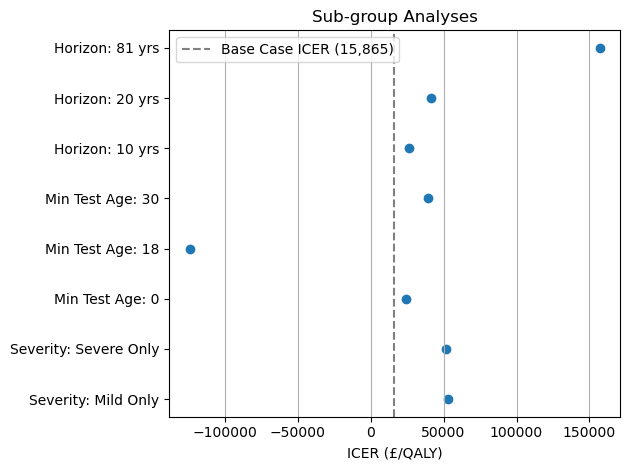

In [10]:
# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []

# Get the mean/base values for all parameters to start from
mean_params_for_subgroup = {}
for k, v in DISTRIBUTIONS.items():
    if v['dist'] == 'beta':
        mean_params_for_subgroup[k] = v['alpha'] / (v['alpha'] + v['beta'])
    elif v['dist'] == 'gamma':
        mean_params_for_subgroup[k] = v['shape'] * v['scale']
    elif v['dist'] == 'lognormal':
        mean_params_for_subgroup[k] = v['scale'] * np.exp(v['s']**2 / 2)
    elif v['dist'] == 'normal':
        mean_params_for_subgroup[k] = v['loc']
    elif v['dist'] == 'uniform':
        mean_params_for_subgroup[k] = (v['low'] + v['high']) / 2
    elif v['dist'] == 'fixed':
        mean_params_for_subgroup[k] = v['value']

# Crucially, derive 'severity_severe_prop' for subgroup analyses
if 'severity_mild_prop' in mean_params_for_subgroup:
    mean_params_for_subgroup['severity_severe_prop'] = 1.0 - mean_params_for_subgroup['severity_mild_prop']

# 1. Severity
# This now means setting severity_mild_prop to 1 or 0
for sev_prop, label in [(1.0, 'Mild Only'), (0.0, 'Severe Only')]:
    current_params_for_run = mean_params_for_subgroup.copy()
    current_params_for_run['severity_mild_prop'] = sev_prop
    current_params_for_run['severity_severe_prop'] = 1.0 - sev_prop # Ensure consistency
    
    dc, dq = run_sim(current_params_for_run, pop_size=15000)
    sg.append({'group': f"Severity: {label}", 'ICER': (dc / dq) if dq != 0 else 0})

# 2. Age at test
for age in [0, 18, 30]:
    current_params_for_run = mean_params_for_subgroup.copy()
    current_params_for_run['min_test_age'] = age
    
    dc, dq = run_sim(current_params_for_run, pop_size=15000)
    sg.append({'group': f"Min Test Age: {age}", 'ICER': (dc / dq) if dq != 0 else 0})

# 3. Time-horizon
# For time-horizon, we run the detailed scenario once with mean parameters
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full['arm'] == 'prospective']
dfr = int_full[int_full['arm'] == 'retrospective']
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    # Check if the year exists in the DataFrame before trying to access it
    if yr in dfp['year'].values and yr in dfr['year'].values:
        c1 = float(dfp.loc[dfp['year'] == yr, 'costs'].values[0])
        c0 = float(dfr.loc[dfr['year'] == yr, 'costs'].values[0])
        q1 = float(dfp.loc[dfp['year'] == yr, 'qalys'].values[0])
        q0 = float(dfr.loc[dfr['year'] == yr, 'qalys'].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append({'group': f"Horizon: {yrs_n} yrs", 'ICER': (dc / dq) if dq != 0 else 0})
    else:
        print(f"Warning: Year {yr} not found in detailed scenario results for time horizon {yrs_n}.")


# Plot
sg_df = cudf.DataFrame(sg)
# Need the base_icer from the fully-parameterized base run, which is from Module 9
# If module 9 was not run, this might fail.
# Let's ensure base_icer is defined from the mean_params_for_subgroup
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df['ICER'].to_arrow().to_pylist(), sg_df['group'].to_arrow().to_pylist(), marker='o')
plt.axvline(base_icer_subgroup, color='grey', linestyle='--', label=f'Base Case ICER ({base_icer_subgroup:,.0f})')
plt.xlabel('ICER (£/QALY)')
plt.title('Sub-group Analyses')
plt.legend()
plt.tight_layout()
plt.grid(axis='x')
plt.show()


--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---


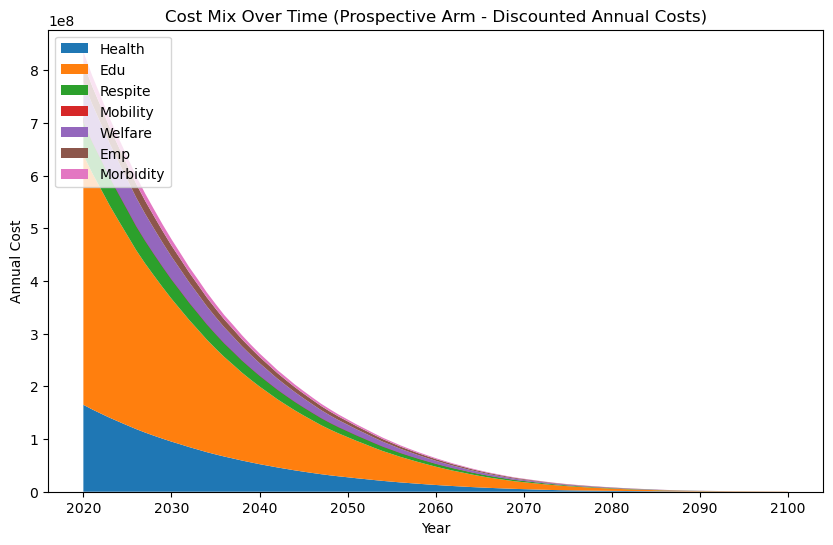

In [11]:
# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# Use mean_params_for_subgroup for the detailed run
(_, _), mix_data_prospective = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data_prospective[mix_data_prospective['arm'] == 'prospective']
cost_cols = ['cost_health', 'cost_edu', 'cost_respite', 'cost_mobility', 'cost_welfare', 'cost_emp', 'cost_morbidity']
years_host = pm['year'].to_arrow().to_pylist()
# Un-cumulate the data for stacking annual costs
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(years_host, *data, labels=[c.replace('cost_', '').capitalize() for c in cost_cols])
plt.legend(loc='upper left')
plt.title('Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)')
plt.xlabel('Year')
plt.ylabel('Annual Cost')
plt.show()



--- Running Module 12: 5-Year Budget Impact ---


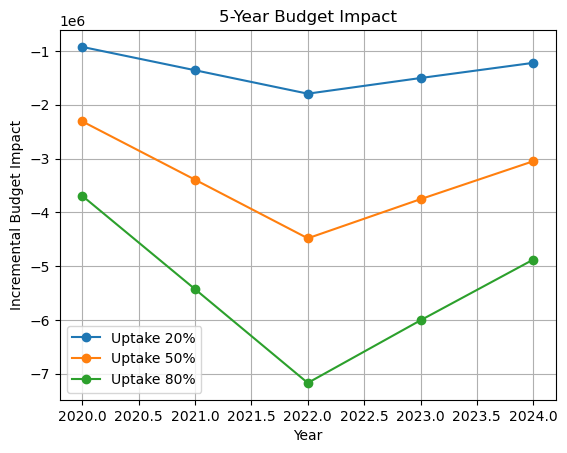

In [12]:
# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Run simulation once to get the cost data
# Use mean_params_for_subgroup for the detailed run
(_, _), df = run_scenario(mean_params_for_subgroup, pop_size=20000)
dfp = df[df['arm'] == 'prospective']
dfr = df[df['arm'] == 'retrospective']

for u in uptakes:
    for yr in yrs:
        # Use 'annual_cost' which is not cumulative
        # Correct way to extract a single scalar from a cuDF Series
        # Check if year exists before trying to get item
        if yr in dfp['year'].values and yr in dfr['year'].values:
            c1 = float(dfp.loc[dfp['year'] == yr, 'annual_cost'].to_cupy().item())
            c0 = float(dfr.loc[dfr['year'] == yr, 'annual_cost'].to_cupy().item())

            # Budget impact is the incremental cost for the new intervention, scaled by uptake
            incremental_cost = c1 - c0
            budg.append({'uptake': u, 'year': yr, 'budget_impact': incremental_cost * u})
        else:
            print(f"Warning: Year {yr} not found in detailed scenario results for budget impact.")


budg_df = cudf.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df['uptake'] == u]
    yrs_h = sub['year'].to_arrow().to_pylist()
    vals = sub['budget_impact'].to_arrow().to_pylist()
    plt.plot(yrs_h, vals, label=f"Uptake {int(u*100)}%", marker='o')
plt.title('5-Year Budget Impact')
plt.xlabel('Year')
plt.ylabel('Incremental Budget Impact')
plt.legend()
plt.grid(True)
plt.show()


--- Running Module 13: Equity by SES Quintile ---


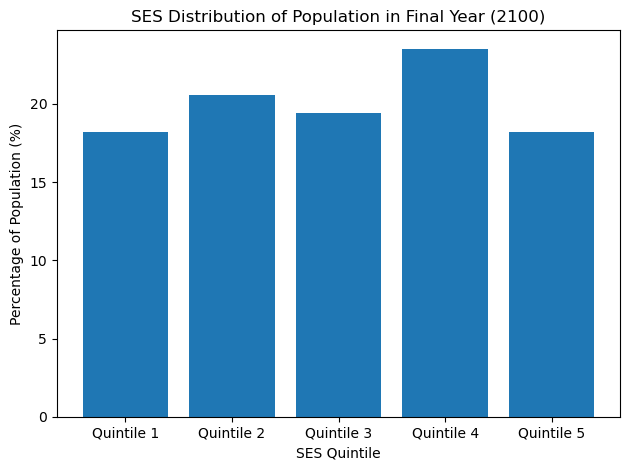

In [13]:
# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
# Use mean_params_for_subgroup for the detailed run
(_, _), eq_int = run_scenario(mean_params_for_subgroup, pop_size=20000)
bas = eq_int[eq_int['arm'] == 'prospective']
# Select the last year of the simulation
# Check if the last year exists in the DataFrame
if YEARS[-1] in bas['year'].values:
    row_series = bas[bas['year'] == YEARS[-1]].iloc[0]

    ses_cols = [f'ses_q{i}_pct' for i in range(5)]
    # Extract scalar values from the series by converting to cupy and then using .item()
    ses_vals = [float(row_series[col].to_cupy().item()) for col in ses_cols]
    labels = [f'Quintile {i+1}' for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f'SES Distribution of Population in Final Year ({YEARS[-1]})')
    plt.xlabel('SES Quintile')
    plt.ylabel('Percentage of Population (%)')
    plt.tight_layout()
    plt.show()
else:
    print(f"Warning: Final year {YEARS[-1]} not found in detailed scenario results for equity analysis.")



--- Running Module 14: PSA Histograms (dCost, dQALY) ---


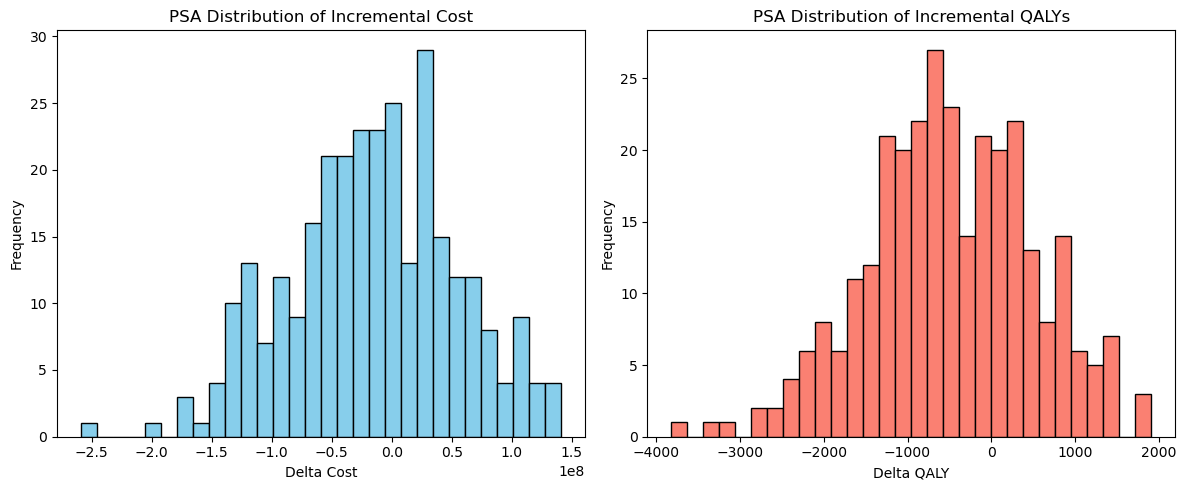

In [14]:
# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
cost_list = psa_df['dCost'].to_arrow().to_pylist()
qaly_list = psa_df['dQALY'].to_arrow().to_pylist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color='skyblue', edgecolor='black')
ax1.set_title('PSA Distribution of Incremental Cost')
ax1.set_xlabel('Delta Cost')
ax1.set_ylabel('Frequency')

ax2.hist(qaly_list, bins=30, color='salmon', edgecolor='black')
ax2.set_title('PSA Distribution of Incremental QALYs')
ax2.set_xlabel('Delta QALY')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()



--- Running Module 15: CEAF ---


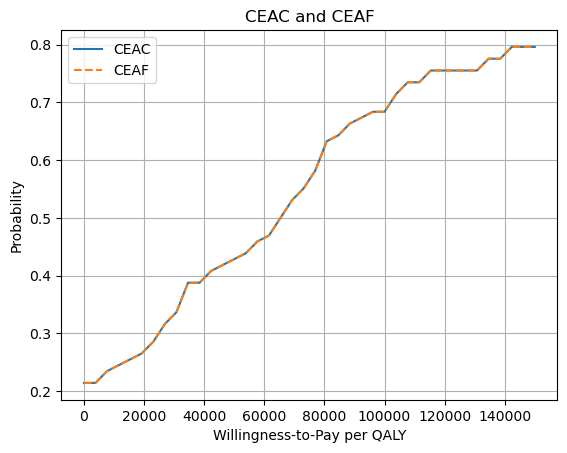

In [15]:
# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# Reuse 'prob' (CEAC probabilities) from Module 8
prob_host = prob.get() # Get the CuPy array to host memory (NumPy array)
ceaf = np.maximum.accumulate(prob_host) # Use numpy for the accumulate operation

plt.figure()
plt.plot(wtp.get(), prob.get(), label='CEAC')
plt.plot(wtp.get(), ceaf, label='CEAF', linestyle='--') # ceaf is already a NumPy array
plt.title('CEAC and CEAF')
plt.xlabel('Willingness-to-Pay per QALY')
plt.ylabel('Probability')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

# Create a summary of the distributions
param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info['dist'] == 'beta':
        summary_str += f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        mean_val = dist_info['alpha'] / (dist_info['alpha'] + dist_info['beta'])
        variance = (dist_info['alpha'] * dist_info['beta']) / ((dist_info['alpha'] + dist_info['beta'])**2 * (dist_info['alpha'] + dist_info['beta'] + 1))
        summary_str += f", Mean: {mean_val:.4f}, Std Dev: {math.sqrt(variance):.4f}"
    elif dist_info['dist'] == 'gamma':
        summary_str += f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        mean_val = dist_info['shape'] * dist_info['scale']
        std_dev = math.sqrt(dist_info['shape'] * dist_info['scale']**2)
        summary_str += f", Mean: {mean_val:.2f}, Std Dev: {std_dev:.2f}"
    elif dist_info['dist'] == 'lognormal':
        summary_str += f", s: {dist_info['s']:.2f}, Scale: {dist_info['scale']:.2f}"
        mean_val = dist_info['scale'] * np.exp(dist_info['s']**2 / 2)
        std_dev = mean_val * np.sqrt(np.exp(dist_info['s']**2) - 1)
        summary_str += f", Mean: {mean_val:.2f}, Std Dev: {std_dev:.2f}"
    elif dist_info['dist'] == 'normal':
        summary_str += f", Mean: {dist_info['loc']:.2f}, Std Dev: {dist_info['scale']:.2f}"
    elif dist_info['dist'] == 'uniform':
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
        mean_val = (dist_info['low'] + dist_info['high']) / 2
        std_dev = math.sqrt((dist_info['high'] - dist_info['low'])**2 / 12)
        summary_str += f", Mean: {mean_val:.2f}, Std Dev: {std_dev:.2f}"
    elif dist_info['dist'] == 'fixed':
        summary_str += f", Value: {dist_info['value']:.2f}"
    
    param_summary_list.append({'parameter': param_name, 'distribution_details': summary_str})

# Add fixed global constants that are not part of DISTRIBUTIONS
param_summary_list.append({'parameter': 'DISCOUNT', 'distribution_details': f"Fixed Value: {DISCOUNT}"})
param_summary_list.append({'parameter': 'POP_SIZE', 'distribution_details': f"Fixed Value: {POP_SIZE}"})
param_summary_list.append({'parameter': 'INFLATION_RATE', 'distribution_details': f"Fixed Value: {INFLATION_RATE}"})
param_summary_list.append({'parameter': 'INFLATION_FACTOR', 'distribution_details': f"Fixed Value: {INFLATION_FACTOR}"})
# Add other fixed arrays that are not varied in PSA
param_summary_list.append({'parameter': 'AGE_BREAKS', 'distribution_details': f"Fixed Array: {AGE_BREAKS.get().tolist()}"})
param_summary_list.append({'parameter': 'AGE_DIST', 'distribution_details': f"Fixed Array: {AGE_DIST.get().tolist()}"})
param_summary_list.append({'parameter': 'LIFE_EXP_CP', 'distribution_details': f"Fixed Array: {LIFE_EXP_CP.get().tolist()}"})
param_summary_list.append({'parameter': 'ABS_MORT', 'distribution_details': f"Fixed Array: {ABS_MORT.get().tolist()}"})
param_summary_list.append({'parameter': 'EMP_CP', 'distribution_details': f"Fixed Array: {EMP_CP.get().tolist()}"})

# Convert tuple keys in FERT_AGE_SPEC to string representations for JSON serialization
fert_age_spec_str_keys = {str(k): v for k, v in FERT_AGE_SPEC.items()}
param_summary_list.append({'parameter': 'FERT_AGE_SPEC_BASE', 'distribution_details': f"Fixed Base Rates (scaled by multiplier): {json.dumps(fert_age_spec_str_keys)}"})

param_df = cudf.DataFrame(param_summary_list)
param_df.to_csv('input_parameters_with_distributions.csv', index=False)
print("Input parameters with distributions saved to input_parameters_with_distributions.csv")


--- Running Module 16: Saving Input Parameter Summary ---
Input parameters with distributions saved to input_parameters_with_distributions.csv


In [17]:
# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
# Published point estimates for comparison
published = {
    'base': {'dCost': 480000, 'dQALY': 6.5, 'ICER': 73846}
}

pub_rows = []
for scen, vals in published.items():
    pub_rows.append({
        'scenario': scen,
        'dCost_pub': vals['dCost'],
        'dQALY_pub': vals['dQALY'],
        'ICER_pub': vals['ICER']
    })
pub_df = cudf.DataFrame(pub_rows)

# Merge with your deterministic simulation output (det_df from Module 6)
df_cmp = det_df.merge(pub_df, on='scenario', how='left')
df_cmp = df_cmp.rename(columns={'dCost': 'dCost_sim', 'dQALY': 'dQALY_sim', 'ICER': 'ICER_sim'})

print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_pandas().to_string()) # Use pandas for cleaner console printing
df_cmp.to_csv('publication_comparison.csv', index=False)
print("Saved comparison to publication_comparison.csv")


--- Running Module 17: Publication Comparison ---
Comparison of Simulation vs. Published Data:
  scenario     dCost_sim    dQALY_sim      ICER_sim  dCost_pub  dQALY_pub  ICER_pub
0     base  1.562525e+08  2308.195556  67694.672398   480000.0        6.5   73846.0
1      low  1.288821e+08  1748.699477  73701.675245        NaN        NaN       NaN
2     high  1.245769e+08  2450.556056  50836.170517        NaN        NaN       NaN
Saved comparison to publication_comparison.csv



--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---
Familial ID Prevalence Sensitivity Results:
   familial_prop         dCost        dQALY          ICER
0       0.100000 -1.651060e+07 -1042.542286  1.583687e+04
1       0.114444 -2.193495e+07  -964.551175  2.274110e+04
2       0.128889 -5.364306e+07 -1197.544437  4.479421e+04
3       0.143333  2.034804e+07   -60.542268 -3.360964e+05
4       0.157778 -1.101128e+06  -663.966648  1.658408e+03
5       0.172222  1.578532e+06  -498.182383 -3.168583e+03
6       0.186667 -3.120719e+07  -619.061485  5.041049e+04
7       0.201111  2.435100e+07    17.667928  1.378260e+06
8       0.215556 -7.165074e+06  -119.935167  5.974123e+04
9       0.230000 -5.086486e+07  -589.821179  8.623776e+04


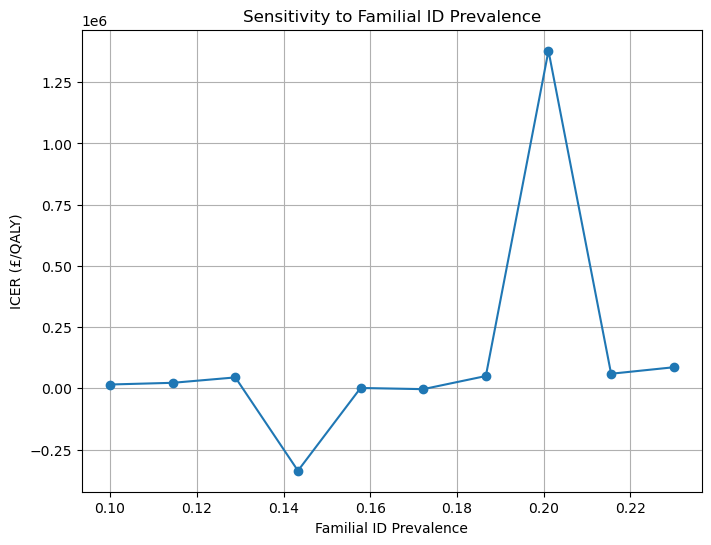

In [18]:
# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
# Get the mean/base values for all parameters to start from
mean_params_for_sens = {}
for k, v in DISTRIBUTIONS.items():
    if v['dist'] == 'beta':
        mean_params_for_sens[k] = v['alpha'] / (v['alpha'] + v['beta'])
    elif v['dist'] == 'gamma':
        mean_params_for_sens[k] = v['shape'] * v['scale']
    elif v['dist'] == 'lognormal':
        mean_params_for_sens[k] = v['scale'] * np.exp(v['s']**2 / 2)
    elif v['dist'] == 'normal':
        mean_params_for_sens[k] = v['loc']
    elif v['dist'] == 'uniform':
        mean_params_for_sens[k] = (v['low'] + v['high']) / 2
    elif v['dist'] == 'fixed':
        mean_params_for_sens[k] = v['value']

# Crucially, derive 'severity_severe_prop' for sensitivity analysis
if 'severity_mild_prop' in mean_params_for_sens:
    mean_params_for_sens['severity_severe_prop'] = 1.0 - mean_params_for_sens['severity_mild_prop']

familial_prevalence_range = np.linspace(0.10, 0.23, 10) # From 10% to 23%
familial_sens_results = []
for f_prop in familial_prevalence_range:
    current_params_for_run = mean_params_for_sens.copy()
    current_params_for_run['familial_prop'] = f_prop # Override familial_prop
    
    dc, dq = run_sim(current_params_for_run, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append({'familial_prop': f_prop, 'dCost': dc, 'dQALY': dq, 'ICER': icer})

familial_sens_df = cudf.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_pandas().to_string())

plt.figure(figsize=(8, 6))
plt.plot(familial_sens_df['familial_prop'].to_arrow().to_pylist(),
         familial_sens_df['ICER'].to_arrow().to_pylist(),
         marker='o', linestyle='-')
plt.xlabel('Familial ID Prevalence')
plt.ylabel('ICER (£/QALY)')
plt.title('Sensitivity to Familial ID Prevalence')
plt.grid(True)
plt.show()


--- Running Module 19: EVPPI Analysis ---
Calculating EVPPI for key parameters...
  - Calculating for: familial_prop
  - Calculating for: yield_wgs
  - Calculating for: u_diag
  - Calculating for: cost_inp_severe


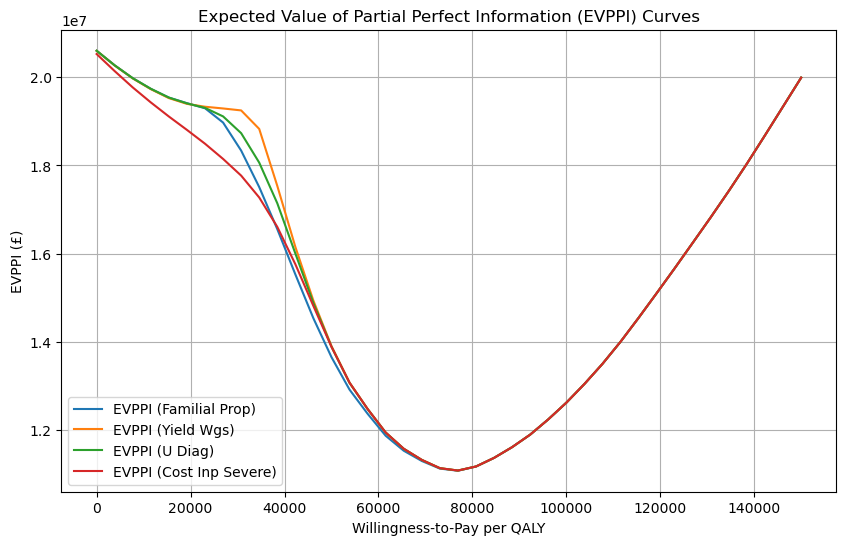

EVPPI analysis complete.


In [19]:
# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")

def calculate_evppi_curve(psa_df_local, param_name, wtp_range):
    """
    Calculates the EVPPI curve for a given parameter over a range of WTP values
    using a simplified regression-based approach.
    """
    evppi_values = []
    
    # Convert dCost and dQALY to CuPy arrays once for efficiency
    dcost_cupy = psa_df_local['dCost'].to_cupy()
    dqaly_cupy = psa_df_local['dQALY'].to_cupy()
    
    # Param values should be from the PSA DataFrame itself
    param_values_cupy = psa_df_local[param_name].to_cupy()

    # Create design matrix for linear regression (NMB ~ intercept + param_value)
    X = cp.vstack([cp.ones(len(psa_df_local)), param_values_cupy]).T

    for wtp_val in wtp_range:
        # Calculate NMB for the current WTP
        nmb_cupy = dqaly_cupy * wtp_val - dcost_cupy

        # Perform linear regression to get predicted NMB
        # lstsq returns (coefficients, residuals, rank, singular_values)
        coeffs = cp.linalg.lstsq(X, nmb_cupy, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # EVPPI approximation: Mean of max(0, NMB) - Mean of max(0, predicted NMB)
        evppi_val = cp.mean(cp.maximum(0, nmb_cupy)) - cp.mean(cp.maximum(0, nmb_predicted))
        evppi_values.append(evppi_val)
        
    return cp.array(evppi_values)

# Parameters for which to calculate EVPPI
# Use a subset of the new parameters for EVPPI, e.g., 'u_diag', 'cost_inp_severe'
parameters_for_evppi_new = ['familial_prop', 'yield_wgs', 'u_diag', 'cost_inp_severe']
evppi_results = {}

print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df.columns: # Ensure the parameter column exists in psa_df
        print(f"  - Calculating for: {param}")
        evppi_curve = calculate_evppi_curve(psa_df, param, wtp)
        evppi_results[param] = evppi_curve.get() # Get to host for plotting
    else:
        print(f"  - Skipping EVPPI for {param}: column not found in PSA results (likely a derived or array parameter).")


# Plotting EVPPI results
if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        plt.plot(wtp.get(), evppi_curve_host, label=f'EVPPI ({param.replace("_", " ").title()})')

    plt.title('Expected Value of Partial Perfect Information (EVPPI) Curves')
    plt.xlabel('Willingness-to-Pay per QALY')
    plt.ylabel('EVPPI (£)')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No EVPPI plots generated as no valid parameters found in PSA results.")

print("EVPPI analysis complete.")


--- Running Module 20: PSA ICER Distribution ---


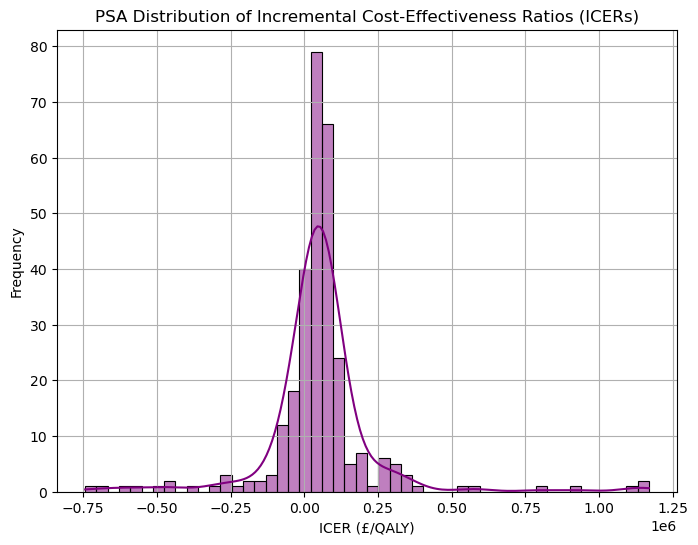

PSA ICER Distribution analysis complete.


In [20]:
# %% [markdown]
## 20. PSA ICER Distribution

print("\n--- Running Module 20: PSA ICER Distribution ---")

# Calculate ICER for each PSA sample
# Handle cases where dQALY is zero to avoid division by zero
psa_icers = []
for i in range(len(psa_df)):
    dc = float(psa_df.loc[i, 'dCost'])
    dq = float(psa_df.loc[i, 'dQALY'])
    if dq != 0:
        psa_icers.append(dc / dq)
    else:
        # Define very large or very small values for infinite/undefined ICERs
        psa_icers.append(np.inf if dc > 0 else (-np.inf if dc < 0 else 0)) 

# Convert to NumPy array for plotting
psa_icers_np = np.array(psa_icers)

# Filter out infinities for histogram plotting, or handle them specifically if desired
# Using a percentile-based capping to avoid extreme outliers distorting the plot
# For example, cap at 99th percentile and 1st percentile
finite_icers = psa_icers_np[np.isfinite(psa_icers_np)]
if len(finite_icers) > 0:
    lower_bound, upper_bound = np.percentile(finite_icers, [1, 99])
    finite_icers_capped = psa_icers_np[(psa_icers_np >= lower_bound) & (psa_icers_np <= upper_bound)]
else:
    finite_icers_capped = np.array([]) # Empty array if no finite ICERs

plt.figure(figsize=(8, 6))
if len(finite_icers_capped) > 0:
    sns.histplot(finite_icers_capped, bins=50, kde=True, color='purple', edgecolor='black')
    plt.title('PSA Distribution of Incremental Cost-Effectiveness Ratios (ICERs)')
    plt.xlabel('ICER (£/QALY)')
    plt.ylabel('Frequency')
    plt.grid(True)
else:
    plt.text(0.5, 0.5, 'No finite ICERs to plot.', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
    plt.title('PSA Distribution of Incremental Cost-Effectiveness Ratios (ICERs)')
    plt.xlabel('ICER (£/QALY)')
    plt.ylabel('Frequency')
    
plt.show()

print("PSA ICER Distribution analysis complete.")


--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---


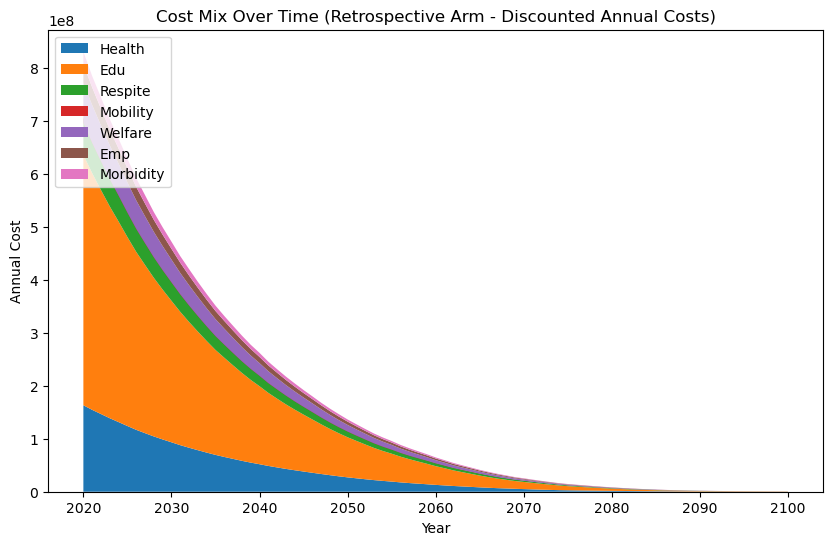

Retrospective Cost Mix analysis complete.


In [21]:
# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# Use mean_params_for_subgroup for the detailed run
# This needs to be run again or passed from Module 11 if it's the same run
# For simplicity, if mix_data_prospective contains both, re-use it.
# If not, it needs to be generated by calling run_scenario again with mean_params.
# Assuming mix_data_prospective already holds both retrospective and prospective data from the run_scenario call in Module 11
# Make sure mix_data_prospective is defined. It's defined in Module 11.
# To ensure it's available, let's re-run run_scenario here using mean_params_for_subgroup or similar.
# A more robust approach might be to store results of run_scenario in a global variable if needed across modules
# or pass it explicitly. For now, assuming it was created in Module 11.
# Re-running run_scenario to ensure mix_data_prospective is available and consistent with other mean_param runs
if 'mix_data_prospective' not in locals():
    print("Warning: mix_data_prospective not found. Re-running run_scenario for Cost-Mix Stacked Area (Retrospective).")
    # Ensure mean_params_for_subgroup is defined for this re-run
    mean_params_for_subgroup_re_run = {}
    for k, v in DISTRIBUTIONS.items():
        if v['dist'] == 'beta':
            mean_params_for_subgroup_re_run[k] = v['alpha'] / (v['alpha'] + v['beta'])
        elif v['dist'] == 'gamma':
            mean_params_for_subgroup_re_run[k] = v['shape'] * v['scale']
        elif v['dist'] == 'lognormal':
            mean_params_for_subgroup_re_run[k] = v['scale'] * np.exp(v['s']**2 / 2)
        elif v['dist'] == 'normal':
            mean_params_for_subgroup_re_run[k] = v['loc']
        elif v['dist'] == 'uniform':
            mean_params_for_subgroup_re_run[k] = (v['low'] + v['high']) / 2
        elif v['dist'] == 'fixed':
            mean_params_for_subgroup_re_run[k] = v['value']
    
    (_, _), mix_data_prospective = run_scenario(mean_params_for_subgroup_re_run, pop_size=20000)

rm = mix_data_prospective[mix_data_prospective['arm'] == 'retrospective']
cost_cols = ['cost_health', 'cost_edu', 'cost_respite', 'cost_mobility', 'cost_welfare', 'cost_emp', 'cost_morbidity']
years_host_r = rm['year'].to_arrow().to_pylist()
data_r = [rm[col].to_arrow().to_pylist() for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(years_host_r, *data_r, labels=[c.replace('cost_', '').capitalize() for c in cost_cols])
plt.legend(loc='upper left')
plt.title('Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)')
plt.xlabel('Year')
plt.ylabel('Annual Cost')
plt.show()

print("Retrospective Cost Mix analysis complete.")
